# Théorie :

**Problème d'un MLP sur une image** : il faut l'applatir en vecteur, on perds la structure spatiale et necessite bcp de poids + instable aux transformation géométrique (translation, symétrie ...).  
On a donc partir sur une structure différentes : **Les CNNs**  
On va utiliser un ensemble de filtres (somme pondérées sur l'imagette ...). Le poids de chaque filtre est commun à toute l'image, chaque filtre devient un détecteur de motif (ligne droite, courbe droite ...)  

Un CNN contient plusieurs couches :  
1. **Convolution** : Produit une feature map par filtre. (Notions à maitriser : noyau, stride, padding, nombre de canaux d'entrée et de sortie.)
2. **Activation (ReLu)** : comme dans le MLP
3. **Pooling** (max pooling) : réduit la taille de la carte et donne une tolérance aux petits décalages.
4. **Aplatissement puis couche dense** : à la fin, on retombe sur un MLP qui classe à partir des motifs détectés (Cette fois, on ne fera pas le MLP entier mais simplifié avec la backprof intégrée à PyTorch)
5. **Sortie** : softmax avec 2 classes (carré/cercle), ou 1 neurone sigmoïde. Loss = cross-entropy

**Apprentissage** : même principe que MLP (boucle {forward, loss, backprog, maj des w} jusqu'à un stop). La nouveauté est que le gradient d'une convolution est lui-même une convolution (avec le filtre retourné), et que celui du max pooling n'est transmis qu'à la position du maximum.

## Plan large proposé par claude
1. Fait (comprendre convolution)
1. Fait (jeu donnée carré/cercle)
2. **Pipeline de données** : normalisation, séparation train/validation/test, mélange, batchs.
3. **Modèle minimal** : 1 à 2 blocs conv + ReLU + pooling, puis une couche dense. Commence petit.
4. **Boucle d'entraînement** : perte, optimiseur, suivi des courbes loss/accuracy (train vs validation).
5. **Évaluation** : accuracy, matrice de confusion, et visualisation des images mal classées.
6. **Comprendre ce que le modèle apprend** : afficher les filtres et les feature maps.
7. **Test final sur tes dessins à la main** : prétraitement identique (redimensionnement, inversion des couleurs si besoin), puis prédiction.
8. **Améliorations** (optionnel) : augmentation de données (translation, rotation, bruit, épaisseur du trait), dropout, comparaison avec ton MLP.

![alt text](TP-CNN-architecture-1.jpg)

### *1. Notions liés à la convolution*
#### *Vocabulaire*
**Noyau :**  
- imagette issus de la matrice qu'on fait glisser sur l'image (3x3 par exemple).
- A chaque position légale, on multiplie terme à terme puis on somme, et on rend 1 résultat. Les poids sont les w issus de l'entrainement.

**Stride (pas) :**  
- Combien de case le noyau se déplace

**Padding :**  
- Présence ou non de bordure rajouté autour de l'entrée
  - padding = 'valid' : aucun rajout. Sortie de taille -2 sur chaque axe
  - padding = 'same' : on rajoute des valeurs sur les contours de l'entrée, qui fait que la sorti est de taille identique à l'entrée (np.pad sur l'entrée)

**Canaux :**  
- Nombre c de matrices (x,y) utilisés pour representer l'image de taille (c,x,y)

#### *Taille impliqué dans la convolution :*
1. **Entrée**
- `C_in` : nombre de canaux d'entrée
- `H` (ou `n`) : hauteur de l'image (donc nbr de lignes)
- `W` (ou `self.self.P`) : largeur ... (nbr de colonnes)
  - Forme de l'entrée : `(C_in, H, W)`   
2. **Hyperparamètres de la couche**
- `C_out` : nombre de filtres, donc nbr canaux de sortie
- `k` : taille du noyau (k*k, souvent 3)
- `s` : stride, le pas de déplacement
- `P`: padding, nombre de cases ajoutées sur les bords (avec `'valid'`, P = 0)  
3. **Intermédiaire : ce que la couche contient**
- Noyau : matrice `k*k` pour un canal
- Filtre : `C_in` noyaux, de forme `(C_in, k, k)`
- Tous les filtres ensemble : forme (`(C_out, C_in, k, k)`)
- Biais : `C_out` valeurs, une par filtre
- Nombre de paramètres appris : `C_out * C_in * k * k + C_out`  
4. **Sortie**
- De forme `(C_out, H_out, W_out)`
- $H_{out} = floor[(H - k + 2P)/s] +1$
- $W_{out} = floor[(W - k + 2P)/s] +1$
  - avec `'valid'` et un stride de 1, on retrouve `H-k+1` et `W-k+1`, soit `H-2` et `W-2` pour k = 3

#### *Resumé :*
**Entrée** **$\to$** Si l'image à plusieurs canaux, on repère l'axe des canaux (le plus petit) et on remet dans l'ordre `(C_in, H, W)` au besoin.  

**Noyaux** **$\to$** On crée `C_out` filtres de forme `(C_in, k, k)` : `(C_out, C_in, k, k)` pour l'ensemble ou un dict ...    
**$\to$** Les poids sont initialisés aléatoirement, et rajoute d'un biais par filtre (soit `C_out` biais tous initialisé à 0)  

**Padding** **$\to$** `'valid'` donne `P=0`, `'same'` donne `P = (k-1)//2`, et un entier est utilisé tel quel. On pad uniquement sur `H` et `W` (pas les canaux)  

**Convolution** **$\to$** pour chaque filtre, on fait glisser la fenetre sur `df`. La map de sortie est de taille `(H_out, W_out)`.  
**$\to$** On itère pour chaque fenetre valide, et on recupere la somme pondérée par poids du noyau (multiplication terme a terme noyau * fenetre), et on rajoute le biais.  

**Sortie** **$\to$** On fait un `np.stack` des maps, ce qui donne un matrice 3D `(C_out, H_out, W_out)`. Chaque couche de sortie correspond à un filtre.  


In [ ]:
def convolution(self, M):
    df = M.copy()
    format = list(df.shape[-2:])

    if self.P > 0:
        df = np.pad(df, [(0, 0)] * (df.ndim - 2) + [(self.P, self.P), (self.P, self.P)])

    N_out = []
    for c, noyau in self.noyau.items():
        N = np.zeros((
            (format[0] - self.k + 2 * self.P) // self.stride + 1,
            (format[1] - self.k + 2 * self.P) // self.stride + 1
        ))
            
        for i in range(N.shape[0]):
            for j in range(N.shape[1]):
                fenetre = df[
                    ...,
                    i * self.stride:i * self.stride + self.k,
                    j * self.stride:j * self.stride + self.k
                ]

                # if fenetre.shape[-2:] == (self.k, self.k):
                N[i,j] = np.sum(fenetre * noyau) + self.biais[c]
        N_out.append(N)
    return np.stack(N_out)

### *2. Notion liées au maxpooling*

In [ ]:
def maxpooling(self, M):
    df = M.copy()
    format = list(df.shape)
    format[-1] = (format[-1] - self.k_maxpooling) // self.stride_maxpooling + 1
    format[-2] = (format[-2] - self.k_maxpooling) // self.stride_maxpooling + 1

    N_out = np.zeros(format)
    for i in range(N_out.shape[-2]):
        for j in range(N_out.shape[-1]):
            fenetre = df[
                ...,
                i * self.stride_maxpooling:i * self.stride_maxpooling + self.k_maxpooling,
                j * self.stride_maxpooling:j * self.stride_maxpooling + self.k_maxpooling
            ]                
            N_out[...,i,j] = np.max(fenetre, axis=(-1,-2))
    return N_out

In [ ]:
rows = []
for i in range(H_out):
    cols = []
    for j in range(W_out):
        fenetre = x[:, :,                               # (N, C_in, k, k)
                    i*self.stride:i*self.stride+self.k,
                    j*self.stride:j*self.stride+self.k]
        cols.append((fenetre[:, None] * self.noyau).sum(dim=(-3,-2,-1)) + self.biais) # (N, C_out)
    rows.append(torch.stack(cols, dim=-1))  # (N, C_out, W_out)
return torch.stack(rows, dim=-2)            # (N, C_out, H_out, W_out)

# devient


fenetre = x.unfold(2, self.k, self.stride).unfold(3,self.k,self.stride) # (N, C_in, H_out, W_out, k, k)
# avec self.noyau de shape (C_out, C_in, k, k) et self.biais de shape (C_out,)
return torch.einsum("nchwab,ocab->nohw", fenetre, self.noyau) + self.biais[None,:,None,None] # (N, C_out, H_out, W_out)

In [ ]:

        rows = []
        for i in range(H_out):
            cols = []
            for j in range(W_out):
                fenetre = x[...,                                # (N, C, k, k)
                            i*self.stride:i*self.stride+self.k,
                            j*self.stride:j*self.stride+self.k]
                cols.append(torch.amax(fenetre, dim=(-2,-1)))   # (N, C)
            rows.append(torch.stack(cols, dim=-1))             # (N, C, W_out)
        return torch.stack(rows,dim=-2)                         # (N, C, H_out, W_out)

# Devient

fenetre = x.unfold(2, self.k, self.stride).unfold(3,self.k,self.stride) # (N, C, H_out, W_out, k, k)
return torch.amax(fenetre, dim=(-2,-1))  # (N, C, H_out, W_out)

## Modèle

In [62]:
import numpy as np
import torch
import torch.nn as nn
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm

In [54]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

X_mnist, y_mnist = fetch_openml('mnist_784', return_X_y=True, as_frame=False)
X_mnist = X_mnist.reshape(-1, 28, 28) / 255.        # (N, 784) -> (N, 28, 28), valeurs dans [0, 1]
y_mnist = y_mnist.astype(np.int64)
indices = resample(
    np.arange(len(X_mnist)),
    n_samples=200,
    replace=False,
    random_state=42
)

# X_mnist = X_mnist[indices]
# y_mnist = y_mnist[indices]

# L'ordre de retour de train_test_split est X_train, X_test, y_train, y_test
X_train, X_test, y_train, y_test = train_test_split(
    X_mnist, y_mnist, test_size=0.2, random_state=42, stratify=y_mnist
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.1, random_state=42, stratify=y_train
)

# Tensors pour le modèle : images (N, 1, 28, 28) float32, labels (N,) int64
X_train = torch.tensor(X_train, dtype=torch.float32).unsqueeze(1).to(device)
X_test  = torch.tensor(X_test,  dtype=torch.float32).unsqueeze(1).to(device)
X_val   = torch.tensor(X_val,   dtype=torch.float32).unsqueeze(1).to(device)
y_train = torch.tensor(y_train, dtype=torch.long).to(device)
y_test  = torch.tensor(y_test,  dtype=torch.long).to(device)
y_val   = torch.tensor(y_val,   dtype=torch.long).to(device)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

torch.Size([50400, 1, 28, 28]) torch.Size([50400]) torch.Size([14000, 1, 28, 28]) torch.Size([14000])


Information pour claude à lire :
On ne veux pas passer par des blocs "boite noir" de pytorch, mais faire a la main les étapes.

In [63]:
class Conv:
    def __init__(self, C_in=1, C_out=6, kernel=3, stride=1, padding="valid"):
        '''
        C_in : nbr de canaux d'entrée - 3 pour RGB ...
        C_out : nombre de filtre et donc nombre de canaux en sortie de convolution
        kernel : taille k du noyau (k x k)
        stride : pas de déplacement de la fenêtre d'application du noyau
        padding : 'valid' (P=0), 'same' (P=(k-1)//2) ou entier >= 0
        '''
        self.C_in, self.C_out = C_in, C_out
        self.k, self.stride = kernel, stride
        self.padding = padding

        # Traduction du padding str -> int
        pad_dict = {'valid': 0, 'same': (self.k - 1)//2}
        if padding in pad_dict:
            self.P = pad_dict[padding]
        elif isinstance(padding, int):
            self.P = padding
        else:
            raise KeyError("Definir padding pour 'valid', 'same' ou entier")

        # Initialisation des poids (C_out, C_in, k, k)
        self.noyau = (torch.randn(C_out, C_in, kernel, kernel, device=device) / (C_in * kernel**2) ** 0.5).requires_grad_()
        self.biais = torch.zeros(C_out, device=device, requires_grad = True)

    def parameters(self):
        return [self.noyau, self.biais]

    def forward(self, x):                   # x : (N, C_in, H, W)
        if x.shape[1] != self.C_in:
            raise ValueError(f"Conv attend {self.C_in} canaux en entrée, recu {x.shape[1]}")
        if self.P > 0:
            x = torch.nn.functional.pad(x, (self.P, self.P, self.P, self.P))
        H_out = (x.shape[-2] - self.k) // self.stride + 1
        W_out = (x.shape[-1] - self.k) // self.stride + 1 
        if H_out <= 0 or W_out <= 0:
            raise ValueError(f"Image trop petite ({x.shape[-2]}x{x.shape[-1]}) pour un noyau {self.k}x{self.k}")

        fenetre = x.unfold(2, self.k, self.stride).unfold(3,self.k,self.stride) # (N, C_in, H_out, W_out, k, k)
        # avec self.noyau de shape (C_out, C_in, k, k) et self.biais de shape (C_out,)
        return torch.einsum("nchwab,ocab->nohw", fenetre, self.noyau) + self.biais[None,:,None,None] # (N, C_out, H_out, W_out)

class ReLu:
    def parameters(self):
        return []

    def forward(self, x):
        return torch.relu(x) # max(0,x)

class MaxPool:
    def __init__(self, kernel=2, stride=2):
        self.k = kernel
        self.stride = stride

    def parameters(self):
        return []

    def forward(self, x):   # x : (N, C, H, W), pas de padding possible
        H_out = (x.shape[-2] - self.k) // self.stride + 1
        W_out = (x.shape[-1] - self.k) // self.stride + 1
        if H_out <= 0 or W_out <= 0:
            raise ValueError(f"Image trop petite ({x.shape[-2]}x{x.shape[-1]}) pour un noyau {self.k}x{self.k}")
        fenetre = x.unfold(2, self.k, self.stride).unfold(3,self.k,self.stride) # (N, C, H_out, W_out, k, k)
        return torch.amax(fenetre, dim=(-2,-1))  # (N, C, H_out, W_out)

class Flatten:
    def parameters(self):
        return []

    def forward(self, x):
        return x.flatten(1)     # (N, C, H, W) -> (N, C*H*W)

class Dense:
    def __init__(self, n_out):
        self.n_in = None    # Connu seulement après le 1er passage
        self.n_out = n_out
        self.W = None
        self.b = None

    def parameters(self):
        if self.W is None:
            raise RuntimeError("Dense enconre non initialisé : faire tourner le modèle (premier passage)")
        return [self.W, self.b]

    def forward(self, x):
        if x.ndim != 2:
            raise ValueError(f"Dense attend une entrée (N, n_in), recu {x.shape} : oubli de Flatten ?")
        if self.W is None:
            self.n_in = x.shape[1]
            self.W = (torch.randn(self.n_in, self.n_out, device=device) / self.n_in ** 0.5).requires_grad_()
            self.b = torch.zeros(self.n_out, device=device, requires_grad=True)
        elif x.shape[1] != self.n_in:
            raise ValueError(f"Dense attend {self.n_in} entrées, recu {x.shape[1]}")
        return x @ self.W + self.b # logits (softmax dans la cross-entropy)

class loss:
    def __init__(self, loss='cross-entropy'):
        self.loss = loss

    def CE(self):
        pass

class Modele:
    def __init__(self, couches, input_shape=(1, 28, 28), EPOCH=100, lr=0.1, batch_size=128, patience=5, eps=1e-4):
        '''
        couches : liste de couches appliquées dans l'ordre
        input_shape : (C, H, W) d'une image, pour le passage à blanc qui fixe la taille des Dense
        '''
        self.couches = couches
        self.input_shape = input_shape
        self.EPOCH = EPOCH
        self.lr = lr
        self.batch_size = batch_size
        self.patience = patience
        self.eps = eps

    def parameters(self):
        p = []
        for c in self.couches:
            p.extend(c.parameters())
            # p.append(c.parameters())
        return p
    
    def forward(self, x):
        for c in self.couches:
            x = c.forward(x)
        return x

    def backward(self, x):
        return 

    def evaluate(self, x, y):
        total_loss, correct = 0., 0
        with torch.no_grad():
            for i in range(0, len(x), self.batch_size):
                xb, yb = x[i:i+self.batch_size], y[i:i+self.batch_size]
                yhat = self.forward(xb)
                total_loss += -torch.log_softmax(yhat, dim=1)[torch.arange(len(yb), device=yhat.device), yb].sum().item()
                correct += (torch.argmax(yhat, dim=1) == yb).sum().item()
        return total_loss / len(x), correct / len(x)
    
    def fit(self, x, y, x_val, y_val):
        self.perf_fit = []
        self.min_loss = float("inf")
        self.best_param = None
        wait = 0
        
        loader = DataLoader(TensorDataset(x,y), batch_size=self.batch_size, shuffle=True, drop_last=True)

        barre_epoch = tqdm(range(self.EPOCH), desc="Epochs")
        for epoch in barre_epoch:
            batch_loss = []
            batch_accuracy = []

            for xb, yb in tqdm(loader, desc="Batchs", leave=False):
                yhat = self.forward(xb)
                p = self.parameters()

                loss = -torch.log_softmax(yhat,dim=1)[torch.arange(yhat.shape[0], device=yhat.device),yb].mean()

                for param in p:
                    param.grad = None
                
                loss.backward()
                with torch.no_grad():
                    for param in p:
                        param -= self.lr * param.grad   # back propagation du gradient (in place fonctionne dans la boucle)

                batch_loss.append(loss.item())
                batch_accuracy.append((torch.argmax(yhat, dim=1) == yb).float().mean().item())

            val_loss, val_accuracy = self.evaluate(x_val, y_val)
            self.perf_fit.append([np.mean(batch_loss), np.mean(batch_accuracy), val_loss, val_accuracy])
            barre_epoch.set_postfix(loss=f"{np.mean(batch_loss):.4f}", val_loss=f"{val_loss:.4f}", val_acc=f"{val_accuracy:.4f}")

            if val_loss < self.min_loss - self.eps:
                wait = 0
                self.min_loss = val_loss
                self.best_params = [param.detach().clone() for param in self.parameters()]
            else:
                wait += 1
                if wait >= self.patience:
                    tqdm.write(f"Early stop at epoch {epoch + 1}")
                    break

        with torch.no_grad():
            for param, best in zip(self.parameters(), self.best_params):
                param.copy_(best)
        
        print(f"Stop apres {len(self.perf_fit)} epochs : val_loss={self.min_loss:.4f}")


    def predict(self, x):
        with torch.no_grad():
            f = self.forward(x).detach()
        return torch.argmax(f, dim=1)

    def accuracy(self, yhat, y):
        return (yhat == y).sum() / len(y)
        


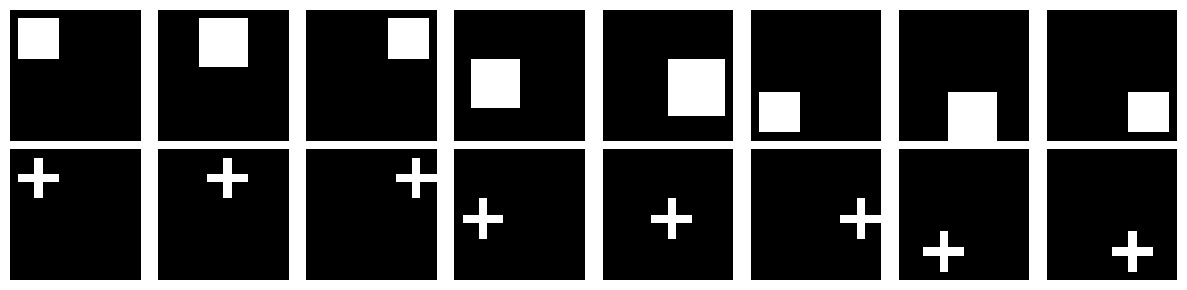

In [59]:
import matplotlib.pyplot as plt

# 16 images : 8 carrés puis 8 croix, de taille 16x16
images = torch.zeros((16, 1, 16, 16), dtype=torch.float32) # (N=16 images, C=1 canal de couleur, H=16, W=16)
y = torch.cat((torch.zeros(8, dtype=int),torch.ones(8,dtype=int)))

# 8 carrés
carres = [
    (1, 1, 5), (5, 1, 6), (10, 1, 5), (2, 6, 6),
    (8, 6, 7), (1, 10, 5), (6, 10, 6), (10, 10, 5)
]

for i, (x0, y0, taille) in enumerate(carres):
    images[i, 0, y0:y0 + taille, x0:x0 + taille] = 1

# 8 croix
croix = [
    (1, 1), (6, 1), (11, 1), (1, 6),
    (6, 6), (11, 6), (3, 10), (8, 10)
]

for i, (x0, y0) in enumerate(croix, start=8):
    images[i, 0, y0:y0 + 5, x0 + 2:x0 + 3] = 1
    images[i, 0, y0 + 2:y0 + 3, x0:x0 + 5] = 1

fig, axes = plt.subplots(2, 8, figsize=(12, 3))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i, 0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")

plt.tight_layout()
plt.show()

# noms distincts de ceux de MNIST (X_train, y_train, ...) pour ne pas les écraser
im_train = torch.cat((images[:6],images[8:-2]))
im_test = torch.cat((images[6:8], images[-2:]))
y_im_train = torch.cat((y[:6],y[8:-2]))
y_im_test = torch.cat((y[6:8], y[-2:]))

In [64]:
c1 = Conv(C_in=1,C_out=10,kernel=3,stride=1,padding='valid')
a1 = ReLu()
m1 = MaxPool(kernel=2,stride=2)
m2 = MaxPool(kernel=3, stride=2)
f1 = Flatten()
d1 = Dense(n_out=10)    # MNIST : 10 classes (chiffres 0 à 9)

couches = [c1, a1, m1, f1, d1]
model = Modele(couches, input_shape=(1, 28, 28), EPOCH=25, lr=0.01, batch_size=64)
# model.forward(images)
# model.parameters()

model.fit(X_train, y_train, X_val, y_val)
yhat = model.predict(X_test)

Epochs:   0%|          | 0/25 [00:00<?, ?it/s]

Batchs:   0%|          | 0/787 [00:00<?, ?it/s]

Batchs:   0%|          | 0/787 [00:00<?, ?it/s]

Batchs:   0%|          | 0/787 [00:00<?, ?it/s]

Batchs:   0%|          | 0/787 [00:00<?, ?it/s]

Batchs:   0%|          | 0/787 [00:00<?, ?it/s]

... (17 outputs left out)

Batchs:   0%|          | 0/787 [00:00<?, ?it/s]

Batchs:   0%|          | 0/787 [00:00<?, ?it/s]

Batchs:   0%|          | 0/787 [00:00<?, ?it/s]

Stop apres 25 epochs : val_loss=0.1289


In [65]:
print("accuracy :", model.accuracy(yhat, y_test).item() * 100, "%")

accuracy : 96.82142734527588 %


In [66]:
# Modele V2
torch.manual_seed(42)

c1 = Conv(C_in=1, C_out=16, kernel=3, stride=1, padding='same')
a1 = ReLu()
m1 = MaxPool(kernel=2, stride=2)
c2 = Conv(C_in=16, C_out=32, kernel=3, stride=1, padding='same')
a2 = ReLu()
m2 = MaxPool(kernel=2, stride=2)
f1 = Flatten()
d1 = Dense(n_out=10)

couches = [c1, a1, m1, c2, a2, m2, f1, d1]  # 28x28 -> 14x14 -> 7x7, Flatten : 32*7*7 = 1568
model = Modele(couches, input_shape=(1, 28, 28), EPOCH=100, lr=0.1, batch_size=128, patience=10, eps=1e-4)

model.fit(X_train, y_train, X_val, y_val)
test_loss, test_acc = model.evaluate(X_test, y_test)   # par batchs, sans graphe de gradient
print(f"test : loss={test_loss:.4f}, accuracy={test_acc * 100:.2f} %")

Epochs:   0%|          | 0/100 [00:00<?, ?it/s]

Batchs:   0%|          | 0/393 [00:00<?, ?it/s]

Batchs:   0%|          | 0/393 [00:00<?, ?it/s]

Batchs:   0%|          | 0/393 [00:00<?, ?it/s]

Batchs:   0%|          | 0/393 [00:00<?, ?it/s]

Batchs:   0%|          | 0/393 [00:00<?, ?it/s]

... (19 outputs left out)

Batchs:   0%|          | 0/393 [00:00<?, ?it/s]

Batchs:   0%|          | 0/393 [00:00<?, ?it/s]

Batchs:   0%|          | 0/393 [00:00<?, ?it/s]

Early stop at epoch 27
Stop apres 27 epochs : val_loss=0.0435
test : loss=0.0435, accuracy=98.59 %


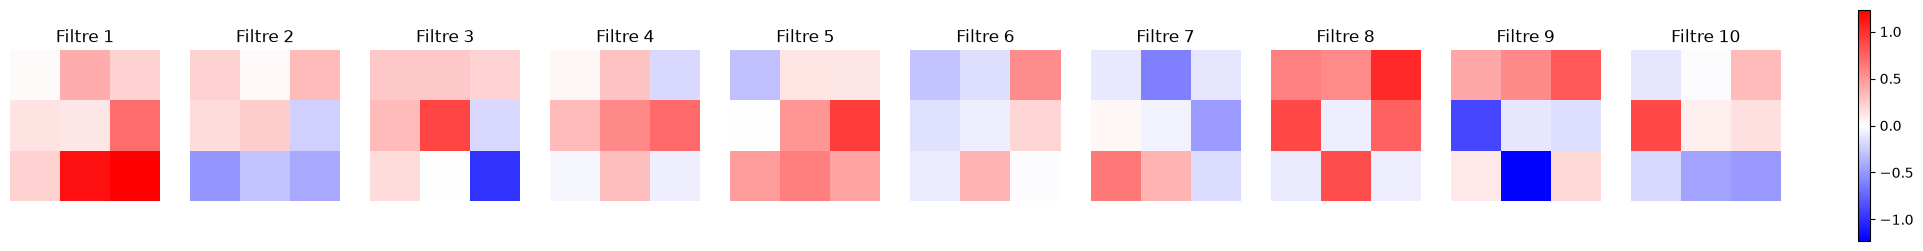

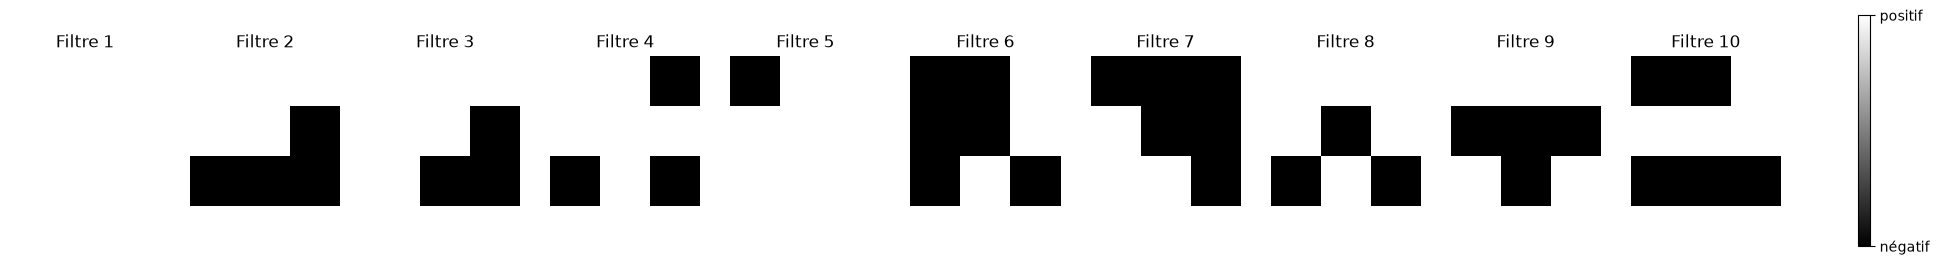

In [48]:
def plot_filtres(model, mode="brut", canal=0):
    """
    mode : "brut"  -> poids appris tels quels (colormap divergente centrée sur 0)
           "signe" -> 0 si poids < 0, 1 si poids >= 0
    canal : canal d'entrée affiché (0 si une seule entrée)
    """
    w = model.parameters()[0].detach()          # (n_filtres, c_in, kh, kw)

    if mode == "brut":
        vmax = w.abs().max().item()
        data, cmap, vmin = w.cpu(), "bwr", -vmax
    elif mode == "signe":
        data, cmap, vmin, vmax = (w.cpu() >= 0).float(), "gray", 0, 1
    else:
        raise ValueError("mode doit être 'brut' ou 'signe'")

    n = len(w)
    fig, axes = plt.subplots(1, n, figsize=(2.5 * n, 3), squeeze=False)
    for i, ax in enumerate(axes[0]):
        im = ax.imshow(data[i, canal], cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(f"Filtre {i + 1}")
        ax.axis("off")

    cb = fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.046, pad=0.04)
    if mode == "signe":
        cb.set_ticks([0, 1]); cb.set_ticklabels(["négatif", "positif"])
    plt.show()

plot_filtres(model, mode="brut")
plot_filtres(model, mode="signe")


In [ ]:
# Modele 3
from sklearn.model_selection import StratifiedKFold

X_all = torch.cat((X_train, X_val))
y_all = torch.cat((y_train, y_val))

def creer_modele():
    couches = [
        Conv(C_in=1, C_out=16, kernel=3, stride=1, padding='same'), ReLu(), MaxPool(kernel=2, stride=2),
        Conv(C_in=16, C_out=32, kernel=3, stride=1, padding='same'), ReLu(), MaxPool(kernel=2, stride=2),
        Flatten(), Dense(n_out=10)
    ]
    return Modele(couches, input_shape=(1, 28, 28), EPOCH=100, lr=0.1, batch_size=128, patience=10, eps=1e-4)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = []
 
for k, (idx_tr, idx_va) in enumerate(skf.split(np.zeros(len(y_all)), y_all.cpu().numpy())):
    idx_tr = torch.tensor(idx_tr, device=device)
    idx_va = torch.tensor(idx_va, device=device)

    torch.manual_seed(42 + k)
    m = creer_modele()
    m.fit(X_all[idx_tr], y_all[idx_tr], X_all[idx_va], y_all[idx_va])

    val_loss, val_acc = m.evaluate(X_all[idx_va], y_all[idx_va])
    scores.append(val_acc)
    print(f"Pli {k + 1}/5 : val_loss={val_loss:.4f}, accuracy={val_acc * 100:.2f} %")

print(f"Accuracy moyenne : {np.mean(scores) * 100:.2f} % (± {np.std(scores) * 100:.2f})")

Epochs:   0%|          | 0/100 [00:00<?, ?it/s]

Batchs:   0%|          | 0/350 [00:00<?, ?it/s]

Batchs:   0%|          | 0/350 [00:00<?, ?it/s]

Batchs:   0%|          | 0/350 [00:00<?, ?it/s]

Batchs:   0%|          | 0/350 [00:00<?, ?it/s]

Batchs:   0%|          | 0/350 [00:00<?, ?it/s]

... (154 outputs left out)

Batchs:   0%|          | 0/350 [00:00<?, ?it/s]

Batchs:   0%|          | 0/350 [00:00<?, ?it/s]

Batchs:   0%|          | 0/350 [00:00<?, ?it/s]

Early stop at epoch 29
Stop apres 29 epochs : val_loss=0.0510
Pli 5/5 : val_loss=0.0510, accuracy=98.46 %
Accuracy moyenne : 98.58 % (± 0.14)


In [68]:
# Modele V4
import time
from sklearn.model_selection import StratifiedKFold

X_all = torch.cat((X_train, X_val))
y_all = torch.cat((y_train, y_val))
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(np.zeros(len(y_all)), y_all.cpu().numpy()))

def creer_modele(canaux=(16, 32), kernel=3, lr=0.1, batch_size=128, EPOCH=30):
    '''canaux : nombre de filtres de chaque bloc Conv + ReLu + MaxPool(2)'''
    couches, c_in = [], 1
    for c_out in canaux:
        couches += [Conv(C_in=c_in, C_out=c_out, kernel=kernel, stride=1, padding='same'), ReLu(), MaxPool(kernel=2, stride=2)]
        c_in = c_out
    couches += [Flatten(), Dense(n_out=10)]
    return Modele(couches, input_shape=(1, 28, 28), EPOCH=EPOCH, lr=lr, batch_size=batch_size, patience=10, eps=1e-4)

# (nom, parametres de creer_modele) : les plus importants d'abord, au cas ou le budget s'epuise
configs = [
    ("base 16-32 k3 lr0.1 bs128", dict(canaux=(16, 32), kernel=3, lr=0.1, batch_size=128)),
    ("lr 0.03",                   dict(lr=0.03)),
    ("lr 0.3",                    dict(lr=0.3)),
    ("batch 64",                  dict(batch_size=64)),
    ("batch 256 lr 0.2",          dict(batch_size=256, lr=0.2)),
    ("filtres 32-64",             dict(canaux=(32, 64))),
    ("kernel 5",                  dict(kernel=5)),
    ("1 seul bloc 32",            dict(canaux=(32,))),
    ("petit 8-16",                dict(canaux=(8, 16))),
]

BUDGET_MIN = 30
t0 = time.time()
resultats = []

for nom, params in configs:
    if (time.time() - t0) / 60 > BUDGET_MIN:
        print(f"Budget de {BUDGET_MIN} min depasse, arret avant : {nom}")
        break

    t1 = time.time()
    scores = []
    try:
        for k, (idx_tr, idx_va) in enumerate(folds):
            idx_tr = torch.tensor(idx_tr, device=device)
            idx_va = torch.tensor(idx_va, device=device)

            torch.manual_seed(42 + k)
            m = creer_modele(**params)
            m.fit(X_all[idx_tr], y_all[idx_tr], X_all[idx_va], y_all[idx_va])
            scores.append(m.evaluate(X_all[idx_va], y_all[idx_va])[1])
    except (TypeError, RuntimeError) as e:     # ex : divergence (nan) -> pas de meilleurs poids sauvegardes
        print(f"{nom} : echec ({e})")
        continue

    resultats.append((nom, np.mean(scores), np.std(scores), (time.time() - t1) / 60))
    print(f">>> {nom} : {np.mean(scores) * 100:.2f} % (± {np.std(scores) * 100:.2f}) en {resultats[-1][3]:.1f} min")
    del m
    torch.cuda.empty_cache()

print(f"\nClassement (temps total : {(time.time() - t0) / 60:.1f} min)")
for nom, moy, std, duree in sorted(resultats, key=lambda r: r[1], reverse=True):
    print(f"{moy * 100:6.2f} % (± {std * 100:.2f})  {duree:4.1f} min  {nom}")


Epochs:   0%|          | 0/30 [00:00<?, ?it/s]

Batchs:   0%|          | 0/350 [00:00<?, ?it/s]

Batchs:   0%|          | 0/350 [00:00<?, ?it/s]

Batchs:   0%|          | 0/350 [00:00<?, ?it/s]

Batchs:   0%|          | 0/350 [00:00<?, ?it/s]

Batchs:   0%|          | 0/350 [00:00<?, ?it/s]

... (727 outputs left out)

Batchs:   0%|          | 0/350 [00:00<?, ?it/s]

Batchs:   0%|          | 0/350 [00:00<?, ?it/s]

Batchs:   0%|          | 0/350 [00:00<?, ?it/s]

KeyboardInterrupt: 